#Multi-armed bandit, exploration-exploitation problem using Epsilon-Greedy method

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class Bandit:
    def __init__(self, n_arms):
        self.n_arms = n_arms
        self.mean = np.random.normal(0, 1, size=n_arms)

    def pull_arms(self, arm):
        return np.random.normal(self.mean[arm], 1)

#epsilon greedy policy

In [3]:
def egp(Q, epsilon):
    if np.random.random() < epsilon:
        return np.random.randint(len(Q))
    else:
        max_val = np.max(Q)
        return np.random.choice(np.where(Q == max_val)[0])

#parameters

In [4]:
n_arms = 10
n_steps = 1000
n_trials = 2000
epsilons = [1, 0.01, 0.1]

In [5]:
average_rewards = np.zeros((len(epsilons), n_steps))
optimal_act_pct = np.zeros((len(epsilons), n_steps))

#epsilon iteration

In [6]:
for i, epsilon in enumerate(epsilons):
    for j in range(n_trials):
        bandit = Bandit(n_arms)
        Q = np.zeros(n_arms)
        N = np.zeros(n_arms)
        optimal_action = np.argmax(bandit.mean)

        for step in range(n_steps):
            action = egp(Q, epsilon)
            reward = bandit.pull_arms(action)

            N[action] += 1
            Q[action] += (reward - Q[action]) / N[action]

            average_rewards[i, step] += reward / n_trials
            if action == optimal_action:
                optimal_act_pct[i, step] += 1 /n_trials

#visualization

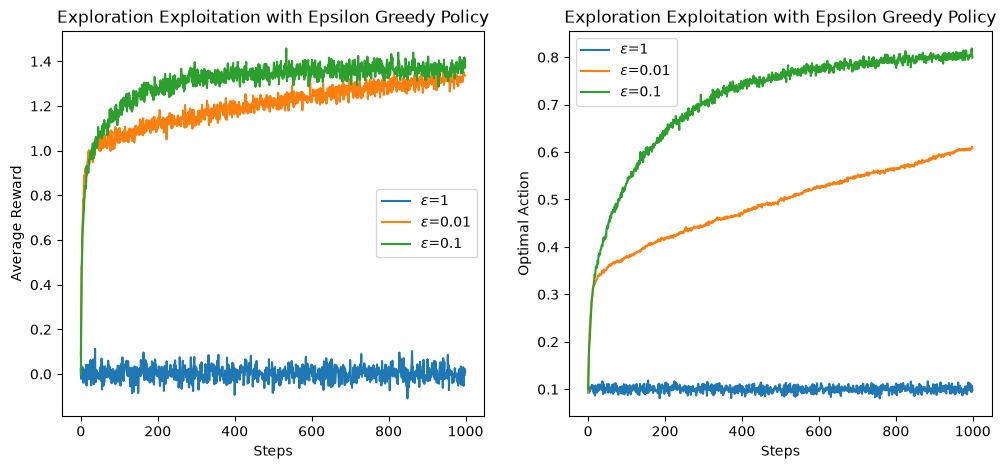

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12,5))

for i, epsilon in enumerate(epsilons):
    axs[0].plot(average_rewards[i], label = r"$\epsilon$={}".format(epsilon))
    axs[1].plot(optimal_act_pct[i], label = r"$\epsilon$={}".format(epsilon))

axs[0].set_xlabel('Steps')
axs[0].set_ylabel('Average Reward')
axs[0].set_title("Exploration Exploitation with Epsilon Greedy Policy")
axs[0].legend()
    
axs[1].set_xlabel('Steps')
axs[1].set_ylabel('Optimal Action')
axs[1].set_title("Exploration Exploitation with Epsilon Greedy Policy")
axs[1].legend()

plt.show()